# Building Heights: Global Building Atlas vs Cadastral

- Cadastral as primary source, GBA as fallback for missing heights and missing buildings.



In [2]:
import os
os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")

In [18]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import duckdb, geopandas as gpd, shapely.wkb
from config import DB_PATH, get_city_cfg, CRS_METRIC, CRS_WGS



In [19]:
# Initialize
CITY = "bologna"
cfg = get_city_cfg(CITY)
src = cfg["data_sources"]

# Connect to DuckDB (if you still need it later)
con = duckdb.connect(str(DB_PATH))
con.execute("LOAD spatial;")

ConnectionException: Connection Error: Can't open a connection to same database file with a different configuration than existing connections

In [20]:
con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("LOAD spatial;")

def load_raw(table: str) -> gpd.GeoDataFrame:
    df = con.execute(f"""
        SELECT * EXCLUDE geometry,
               ST_AsWKB(geometry) AS geom_wkb
        FROM raw.{table}
    """).df()
    return gpd.GeoDataFrame(
        df.drop(columns="geom_wkb"),
        geometry=df["geom_wkb"].apply(lambda b: shapely.wkb.loads(bytes(b))),
        crs=CRS_METRIC
    )

cadastral_raw = load_raw(f"{CITY}_cadastral")   
gba_raw = load_raw(f"{CITY}_gba")  
boundary = load_raw(f"{CITY}_boundary")

CatalogException: Catalog Error: Table with name bologna_cadastral does not exist!
Did you mean "milano_boundary"?

LINE 4:         FROM raw.bologna_cadastral
                     ^

## 1. Load & Clean Data

**Preprocessing:**
- Clip both datasets to Bologna municipal boundary (EPSG:32632)
- Filter buildings with footprint area <= 5 m2 (removes shelters, garages, artefacts)
- Cadastral height = `altezza_gr`, fallback to `quota_gron - quota_pied` where missing

In [ ]:
# Load
bologna_boundary = gpd.read_file("data/bologna_boundary.gpkg", driver='GPKG').to_crs("EPSG:32632")
global_atlas  = gpd.read_file("data/3trees/bologna_gba.geojson").to_crs("EPSG:32632")
cadastral_raw    = gpd.read_file("data/3trees/.bologna_cadastral_raw.geojson" ).to_crs("EPSG:32632")

# GBA: clip + filter
global_atlas= gpd.clip(global_atlas, bologna_boundary)
global_atlas["area_m2"] = global_atlas.geometry.area
global_atlas = global_atlas[global_atlas["area_m2"] > 5].copy()
global_atlas["height_filtered"] = global_atlas["height"].fillna(0)

# Cadastral: clip + filter + compute height
cadastral_clipped  = gpd.clip(cadastral_raw, bologna_boundary)
cadastral_clipped["area_m2"] = cadastral_clipped.geometry.area
cadastral_clipped  = cadastral_clipped[cadastral_clipped["area_m2"] > 5].copy()
cadastral_clipped["height"]  = cadastral_clipped["altezza_gr"].fillna(
    cadastral_clipped["quota_gron"] - cadastral_clipped["quota_pied"]
)
cadastral_clipped["height_filtered"] = cadastral_clipped["height"].where(
    cadastral_clipped["height"] > 0, 0
)

print("1. DATA SUMMARY  (area > 5 m2, clipped to Bologna)")
print(f" GBA = Total buildings   : {len(global_atlas):>8,}")
print(f" Height > 0  : {(global_atlas['height_filtered'] > 0).sum():>8,}")
print(f"Zero/missing : {(global_atlas['height_filtered'] <= 0).sum():>8,}")


print(f"CAD = Total buildings   : {len(cadastral_clipped):>8,}")
print(f" Height > 0  : {(cadastral_clipped['height_filtered'] > 0).sum():>8,}")
print(f"Zero/missing  : {(cadastral_clipped['height_filtered'] <= 0).sum():>8,}")

/opt/anaconda3/lib/python3.11/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver GPKG does not support open option DRIVER
  return ogr_read(


DataSourceError: data/global_atlas_height.geojson: No such file or directory

## 2. Geometry Matching

Spatial join by intersection. For buildings matched to multiple candidates, keep the one with the largest overlap area.

In [81]:
left  = global_atlas[["geometry", "height_filtered"]].rename(columns={"height_filtered": "height_left"})
right = cadastral_clipped[["geometry", "height_filtered"]].rename(columns={"height_filtered": "height_right"})

# Single raw join — used for both best_per_gba and best_per_cad
joined_raw = gpd.sjoin(left, right, how="inner", predicate="intersects")

right_geoms = right.geometry
joined_raw["overlap_area"] = joined_raw.apply(
    lambda row: row.geometry.intersection(right_geoms.loc[row["index_right"]]).area,
    axis=1
)

# One row per GBA building — used for height comparison and gap-filling
best_per_gba = (joined_raw
    .sort_values("overlap_area", ascending=False)
    .loc[lambda df: ~df.index.duplicated(keep="first")]
)

# One row per cadastral building — used for cadastral-side coverage counts only
best_per_cad = (joined_raw
    .sort_values("overlap_area", ascending=False)
    .loc[lambda df: ~df["index_right"].duplicated(keep="first")]
)

joined_all = best_per_gba.copy()

n_gba_matched       = best_per_gba.index.nunique()
n_cadastral_matched = best_per_cad["index_right"].nunique()

print("2. GEOMETRY MATCHING")
print(f"  Total matched (best overlap per GBA) : {len(joined_all):>8,}")
print(f"  GBA  matched : {n_gba_matched:,}  |  only : {len(global_atlas)-n_gba_matched:,}")
print(f"  CAD  matched : {n_cadastral_matched:,}  |  only : {len(cadastral_clipped)-n_cadastral_matched:,}")

2. GEOMETRY MATCHING
  Total matched (best overlap per GBA) :   50,974
  GBA  matched : 50,974  |  only : 2,391
  CAD  matched : 57,817  |  only : 7,241


## COMPARISON OF MATCHING STRATEGIES

sjoin_nearest with max_distance results: Centroid distance threshold Match by nearest centroid within X metres instead of overlap. (Max distance = 5 => 51,956 | Max distance = 10 => 52, 329)

sjoin - intersect + choose the best overlap: total matched (best overlap per GBA) :  50,974

Intersection over unio filter out large amount of data - therefore I would not go for that approach: IoU > 0.3  : 43,586, IoU > 0.5 : 34,545

Three matching strategies are evaluated: 
- intersection-based (50,974 matched)
- centroid distance ≤10m (52,329)
- intersection over unio: filtered (43,586 at IoU>0.3)

Now I use sjoin intersection with largest overlap approach = it requires physical overlap between polygons, is parameter-free, and the marginal gain from distance-based matching (~2.6%) does not justify the risk of false matches between adjacent buildings.

## 3. Height Comparison

Compare heights only where **both** datasets have height > 0.
Note: GBA always predicts a height (ML-derived), so the limiting factor is always the cadastral side.

In [1]:
# Subset: both have height > 0
joined_heights = joined_all[
    (joined_all["height_left"]  > 0) &
    (joined_all["height_right"] > 0)
].copy()
joined_heights["height_diff"] = (joined_heights["height_left"] - joined_heights["height_right"]).abs()
joined_heights["signed_diff"] =  joined_heights["height_left"] - joined_heights["height_right"]

# Stats
thresholds = [1, 2, 3, 5, 8, 10]
mean_bias = joined_heights["signed_diff"].mean()
threshold_75  = joined_heights["height_diff"].quantile(0.75)
median = joined_heights["height_diff"].median()
mad = np.median(np.abs(joined_heights["height_diff"] - median))
threshold_mad = median + 2 * mad

# Within-matched breakdown
n_geom_gba_has_height = (joined_all["height_left"]  > 0).sum()
n_geom_cad_has_height = (joined_all["height_right"] > 0).sum()
n_height_in_both  = len(joined_heights)
n_matched_cad_missing = len(joined_all) - n_geom_cad_has_height

print("3. HEIGHT COMPARISON")
print(f"Geometrically matched  {len(joined_all):>8,}")
print(f"Matched + height in GBA : {n_geom_gba_has_height:>8,}  (GBA always has height)")
print(f"Matched + height in cadastral : {n_geom_cad_has_height:>8,}")
print(f"Matched + height in BOTH : {n_height_in_both:>8,}  <- used for comparison")
print(f"Matched but cadastral missing ht : {n_matched_cad_missing:>8,}  <- candidates for gap-fill")

print(f"  Threshold sensitivity (n={n_height_in_both:,}):")
for t in thresholds:
    n   = (joined_heights["height_diff"] <= t).sum()
    pct = (joined_heights["height_diff"] <= t).mean() * 100
    print(f"+/-{t:>2} m  =>  {n:>6,}  ({pct:.1f}%)")

print(f"Mean signed bias (GBA - cadastral) : {mean_bias:>+8.2f} m")
print(f"75th percentile of differences : {threshold_75:>8.2f} m")
print(f"Robust MAD threshold : {threshold_mad:>8.2f} m")

print(" stats of height differences:")
print(joined_heights["height_diff"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]).round(2).to_string())

NameError: name 'joined_all' is not defined

## 4. Coverage Summary

Points 1-3: height-based (height > 0)
Points 4-5: geometry-based (building polygon exists) + filtered to height > 0

All counts use same base: area > 5 m2, clipped to Bologna.

In [69]:
# GBA: which buildings have no cadastral geometry match
matched_gba     = gpd.sjoin(
    global_atlas[["geometry", "height_filtered"]],
    cadastral_clipped[["geometry"]],
    how="left", predicate="intersects"
)
n_gba_matched   = matched_gba[matched_gba["index_right"].notna()].index.nunique()
gba_only_idx    = matched_gba[matched_gba["index_right"].isna()].index.unique()
gba_no_cadastral = global_atlas.loc[gba_only_idx].copy()

# Cadastral: which buildings have no GBA geometry match
matched_cadastral   = gpd.sjoin(
    cadastral_clipped[["geometry"]],
    global_atlas[["geometry"]],
    how="left", predicate="intersects"
)
n_cadastral_matched = matched_cadastral[matched_cadastral["index_right"].notna()].index.nunique()
cadastral_only_idx  = matched_cadastral[matched_cadastral["index_right"].isna()].index.unique()

# Counts
total_gba        = len(global_atlas)
total_cadastral  = len(cadastral_clipped)
n_gba_only       = len(global_atlas)      - n_gba_matched
n_cadastral_only = len(cadastral_clipped) - n_cadastral_matched

# Height > 0 within unmatched
n_gba_only_height       = (gba_no_cadastral["height_filtered"] > 0).sum()
n_cadastral_only_height = (cadastral_clipped.loc[cadastral_only_idx, "height_filtered"] > 0).sum()

n_matched_cad_has_height = (best_per_cad["height_right"] > 0).sum()

print(f"CAD height check: {n_matched_cad_has_height:,} + {n_cadastral_only_height:,} = "
      f"{n_matched_cad_has_height + n_cadastral_only_height:,} (should = 54,372)")

print("4. COVERAGE SUMMARY  (area > 5 m2, height > 0)")
print(f"  1. Height in cadastral (total)            : {(cadastral_clipped['height_filtered'] > 0).sum():>8,}  (of {total_cadastral:,})")
print(f"  2. Height in GBA (total)                  : {(global_atlas['height_filtered'] > 0).sum():>8,}  (of {total_gba:,})")
print(f"  3. Height in both (geom + height > 0)     : {n_height_in_both:>8,}")

print(f"  4. GBA only — all polygons                : {n_gba_only:>8,}  (of {total_gba:,})")
print(f"     GBA only — height > 0                  : {n_gba_only_height:>8,}")
print(f"  5. Cadastral only — all polygons          : {n_cadastral_only:>8,}  (of {total_cadastral:,})")
print(f"     Cadastral only — height > 0            : {n_cadastral_only_height:>8,}")



CAD height check: 52,671 + 1,701 = 54,372 (should = 54,372)
4. COVERAGE SUMMARY  (area > 5 m2, height > 0)
  1. Height in cadastral (total)            :   54,372  (of 65,058)
  2. Height in GBA (total)                  :   53,365  (of 53,365)
  3. Height in both (geom + height > 0)     :   48,832
  4. GBA only — all polygons                :    2,391  (of 53,365)
     GBA only — height > 0                  :    2,391
  5. Cadastral only — all polygons          :    7,241  (of 65,058)
     Cadastral only — height > 0            :    1,701


## 5. Gap-Filling

**Case A:** Cadastral geometry exists but height <= 0 -> fill from nearest GBA building within 2 m buffer.
Filled count (6,881) > strict geometry match count (2,142) because the 2 m buffer catches nearby non-overlapping GBA buildings — intentional.

**Case B:** GBA building has no cadastral counterpart at all -> append polygon + height directly.

In [70]:

# Base: all cadastral buildings
bologna_buildings_final = cadastral_clipped[["geometry", "height_filtered"]].copy()
bologna_buildings_final = bologna_buildings_final.rename(columns={"height_filtered": "height"})
bologna_buildings_final["source"] = "cadastral"

n_cad_base       = len(bologna_buildings_final)
n_cad_has_height = (bologna_buildings_final["height"] > 0).sum()
n_needs_fill     = (bologna_buildings_final["height"] <= 0).sum()

# Case A: fill missing heights from GBA (2m buffer)
needs_fill_mask = bologna_buildings_final["height"] <= 0
needs_fill      = bologna_buildings_final[needs_fill_mask].copy()
needs_fill_buf  = needs_fill.copy()
needs_fill_buf["geometry"] = needs_fill_buf.geometry.buffer(2)

gba_valid   = global_atlas[global_atlas["height_filtered"] > 0][["geometry", "height_filtered"]].copy()
joined_fill = gpd.sjoin(needs_fill_buf[["geometry"]], gba_valid, how="left", predicate="intersects")
best_fill   = joined_fill.dropna(subset=["height_filtered"]).groupby(level=0)["height_filtered"].first()

bologna_buildings_final.loc[best_fill.index, "height"] = best_fill.values
bologna_buildings_final.loc[best_fill.index, "source"] = "cadastral_gba_fill"

n_filled        = len(best_fill)
n_still_missing = (bologna_buildings_final["height"] <= 0).sum()

# Case B: append GBA-only buildings (height > 0 only)
gba_no_cadastral_h = gba_no_cadastral[gba_no_cadastral["height_filtered"] > 0].copy()
gba_extra = gba_no_cadastral_h[["geometry", "height_filtered"]].rename(
    columns={"height_filtered": "height"}
).copy()
gba_extra["source"] = "gba_only"
n_gba_appended = len(gba_extra)

# Concatenate
bologna_buildings_final = pd.concat([bologna_buildings_final, gba_extra], ignore_index=True)
bologna_buildings_final = gpd.GeoDataFrame(
    bologna_buildings_final, geometry="geometry", crs="EPSG:32632"
)

print("5. GAP-FILLING")
print(f"  Cadastral base buildings         : {n_cad_base:>8,}")
print(f"  Already have height              : {n_cad_has_height:>8,}")
print(f"  Needing fill (height <= 0)       : {n_needs_fill:>8,}")
print(f"  Filled via GBA (2m buffer)       : {n_filled:>8,}")
print(f"  Still missing after fill         : {n_still_missing:>8,}")
print(f"  GBA-only buildings appended      : {n_gba_appended:>8,}")

5. GAP-FILLING
  Cadastral base buildings         :   65,058
  Already have height              :   54,372
  Needing fill (height <= 0)       :   10,686
  Filled via GBA (2m buffer)       :    6,881
  Still missing after fill         :    3,805
  GBA-only buildings appended      :    2,391


## 6. Final Dataset Summary

In [2]:
n_from_cadastral = ((bologna_buildings_final["source"] == "cadastral") &
                    (bologna_buildings_final["height"] > 0)).sum()
n_from_gba_fill  = (bologna_buildings_final["source"] == "cadastral_gba_fill").sum()
n_from_gba_only  = (bologna_buildings_final["source"] == "gba_only").sum()
total_final      = len(bologna_buildings_final)
n_with_height    = (bologna_buildings_final["height"] > 0).sum()
n_zero           = (bologna_buildings_final["height"] <= 0).sum()

print("6. FINAL DATASET")
print(f"  Heights from cadastral           : {n_from_cadastral:>8,}")
print(f"  Heights from GBA (gap-fill)      : {n_from_gba_fill:>8,}")
print(f"  Buildings solely from GBA        : {n_from_gba_only:>8,}")
print(f"  Total with height > 0            : {n_with_height:>8,} ")
print(f"  Still zero/missing               : {n_zero:>8,}")
print(f"  Total buildings                  : {total_final:>8,} ")

bologna_buildings_final.to_file("data/bologna_buildings_final.gpkg", driver="GPKG")
print(f"Saved: data/bologna_buildings_final.gpkg")

NameError: name 'bologna_buildings_final' is not defined

## 7. QGIS Export

Export GBA and cadastral layers tagged with match_status for visual comparison.
Style by `match_status`: matched / gba_only / cadastral_only

In [ ]:
global_atlas["match_status"] = "matched"
global_atlas.loc[gba_only_idx, "match_status"] = "gba_only"

cadastral_clipped["match_status"] = "matched"
cadastral_clipped.loc[cadastral_only_idx, "match_status"] = "cadastral_only"

final_buildings = "{CITY}_buildings.gpkg"
global_atlas[["geometry", "height_filtered", "match_status"]].to_file(
    final_buildings, layer="gba_buildings", driver="GPKG")
cadastral_clipped[["geometry", "height_filtered", "match_status"]].to_file(
    final_buildings, layer="cadastral_buildings", driver="GPKG")

In [ ]:
def gdf_to_duckdb(con, gdf: gpd.GeoDataFrame, schema_table: str, city: str):
    df = gdf.copy()
    df["geom_wkb"] = df.geometry.apply(lambda g: g.wkb if g is not None else None)
    df = df.drop(columns="geometry")
    con.register("_tmp", df)
    con.execute(f"""
        CREATE OR REPLACE TABLE {schema_table} AS
        SELECT '{city}' AS city,
               * EXCLUDE geom_wkb,
               ST_GeomFromWKB(geom_wkb) AS geometry
        FROM _tmp;
    """)
    con.unregister("_tmp")

con = duckdb.connect(str(DB_PATH))
con.execute("LOAD spatial;")
con.execute("CREATE SCHEMA IF NOT EXISTS preprocessing;")

#individual source layers 
gdf_to_duckdb(con, cadastral_clipped, f"preprocessing.{CITY}_buildings_cadastral", CITY)
print(f"  preprocessing.{CITY}_buildings_cadastral: {len(cadastral_clipped):,} features")

gdf_to_duckdb(con, global_atlas, f"preprocessing.{CITY}_buildings_gba", CITY)
print(f"  preprocessing.{CITY}_buildings_gba: {len(global_atlas):,} features")

# ── merged final result 
gdf_to_duckdb(con, {CITY}_buildings_final, f"preprocessing.{CITY}_buildings", CITY)
print(f"  preprocessing.{CITY}_buildings: {len({CITY}_buildings_final):,} features")
print({CITY}_buildings_final["source"].value_counts().to_string())

con.close()

# ── optional: export back to GeoPackage ──────────────────────────────────────
# con = duckdb.connect(str(DB_PATH))
# con.execute("LOAD spatial;")
# df = con.execute(f"""
#     SELECT * EXCLUDE geometry,
#            ST_AsWKB(geometry) AS geom_wkb
#     FROM preprocessing.{CITY}_buildings
# """).df()
# gdf = gpd.GeoDataFrame(
#     df.drop(columns="geom_wkb"),
#     geometry=df["geom_wkb"].apply(lambda b: shapely.wkb.loads(bytes(b))),
#     crs=CRS_METRIC
# )
# gdf.to_file(cfg["data_sources"]["buildings"], layer="buildings", driver="GPKG")
# print(f"saved {len(gdf):,} features → {cfg['data_sources']['buildings']}")
# con.close()

## 8. Plots

In [ ]:
# Plot 1: Building coverage stacked bar
fig, ax = plt.subplots(figsize=(7, 5))

categories     = ["GBA", "Cadastral"]
matched_counts = [n_gba_matched, n_cadastral_matched]
only_counts    = [n_gba_only,    n_cadastral_only]
only_colors    = ["#8400FF",     "#21E5F3"]

ax.bar(categories, matched_counts, color="#AF7D4C")
ax.bar(categories, only_counts, bottom=matched_counts, color=only_colors)

for i, (m, u) in enumerate(zip(matched_counts, only_counts)):
    ax.text(i, m / 2,     f"{m:,}\nmatched", ha="center", va="center", color="white", fontsize=7, fontweight="bold")
    ax.text(i, m + u / 2, f"{u:,}\nonly",    ha="center", va="center", color="white", fontsize=7, fontweight="bold")

ax.legend(handles=[
    mpatches.Patch(color="#AF7D4C", label="Matched"),
    mpatches.Patch(color="#8400FF", label="GBA only"),
    mpatches.Patch(color="#21E5F3", label="Cadastral only")
], fontsize=8)
ax.set_title("Building Coverage: GBA vs Cadastral", fontweight="bold", fontsize=10)
ax.set_ylabel("Number of Buildings", fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.tick_params(axis='both', labelsize=8)
plt.tight_layout()
plt.savefig("plot_building_coverage.png", dpi=150, bbox_inches="tight")
plt.show()

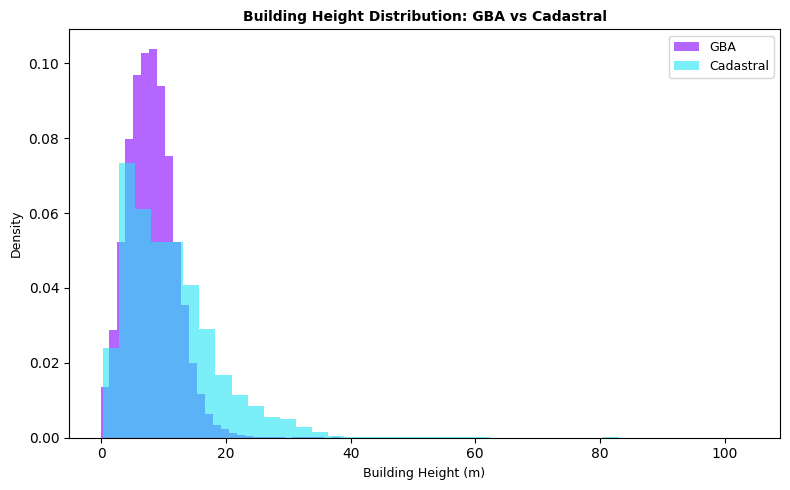

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(global_atlas[global_atlas["height_filtered"] > 0]["height_filtered"],
        bins=40, alpha=0.6, color="#8400FF", label="GBA",
        density=True)  #normalise to probability density
ax.hist(cadastral_clipped[cadastral_clipped["height_filtered"] > 0]["height_filtered"],
        bins=40, alpha=0.6, color="#21E5F3", label="Cadastral",
        density=True)

ax.set_xlabel("Building Height (m)", fontsize=9)
ax.set_ylabel("Density", fontsize=9)  
ax.set_title("Building Height Distribution: GBA vs Cadastral", fontweight="bold", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("plot_height_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Plot 3: Height scatter (matched buildings, height > 0 in both)
fig, ax = plt.subplots(figsize=(6, 6))
sample = joined_heights.sample(min(3000, len(joined_heights)), random_state=42)

ax.scatter(sample["height_right"], sample["height_left"],
           alpha=0.2, s=5, color="#2196F3")

max_h = max(sample["height_right"].max(), sample["height_left"].max())
bias  = sample["signed_diff"].mean()

ax.plot([0, max_h], [0, max_h],         color="red",    linewidth=1.5, linestyle="--", label="Perfect agreement (1:1)")
ax.plot([0, max_h], [bias, max_h+bias], color="orange", linewidth=1.5, linestyle="--", label=f"Mean bias ({bias:+.1f} m)")

ax.set_xlabel("Cadastral Height (m)", fontsize=9)
ax.set_ylabel("GBA Height (m)", fontsize=9)
ax.set_title("Height Agreement: GBA vs Cadastral\nMatched buildings (height > 0 in both)",
             fontweight="bold", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("plot_height_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

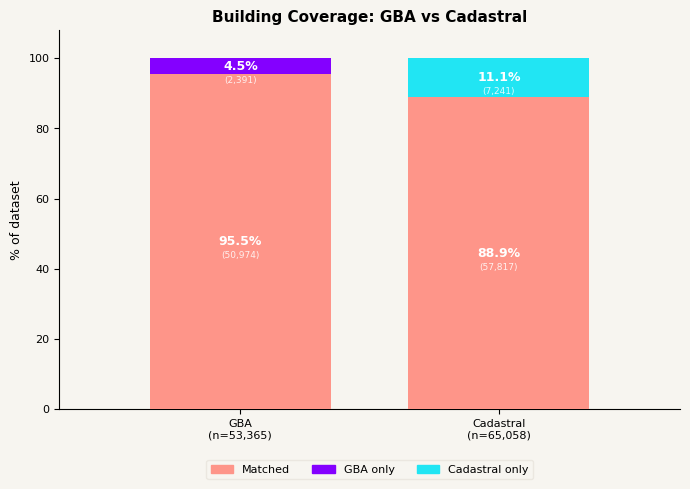

In [51]:
fig, ax = plt.subplots(figsize=(7, 5), facecolor="#F7F5F0")
ax.set_facecolor("#F7F5F0")

ax.bar(categories, [pct_gba_matched, pct_cad_matched],
       color="#FE9589", width=0.7, zorder=3)
ax.bar(categories, [pct_gba_only, pct_cad_only],
       bottom=[pct_gba_matched, pct_cad_matched],
       color=["#8400FF", "#21E5F3"], width=0.7, zorder=3)

# Annotations — only show % in the bar, raw count below as smaller text
for i, (m, u, rm, ru) in enumerate(zip(
    [pct_gba_matched, pct_cad_matched],
    [pct_gba_only,    pct_cad_only],
    [n_gba_matched,   n_cadastral_matched],
    [n_gba_only,      n_cadastral_only]
)):
    # matched segment
    ax.text(i, m / 2,      f"{m:.1f}%",   ha="center", va="center",
            color="white", fontsize=9,  fontweight="bold")
    ax.text(i, m / 2 - 4,  f"({rm:,})",  ha="center", va="center",
            color="white", fontsize=6.5, alpha=0.85)
    # only segment — skip if too small to label
    if u > 2:
        ax.text(i, m + u / 2,     f"{u:.1f}%",  ha="center", va="center",
                color="white", fontsize=9,  fontweight="bold")
        ax.text(i, m + u / 2 - 4, f"({ru:,})",  ha="center", va="center",
                color="white", fontsize=6.5, alpha=0.85)

ax.legend(handles=[
    mpatches.Patch(color="#FE9589", label="Matched"),
    mpatches.Patch(color="#8400FF", label="GBA only"),
    mpatches.Patch(color="#21E5F3", label="Cadastral only")
], fontsize=8, frameon=True, facecolor="#F7F5F0", edgecolor="#E8E4DC",
   loc="upper center",
   bbox_to_anchor=(0.5, -0.12),  # below the plot
   ncol=3)                        # all 3 items in one row

ax.set_ylabel("% of dataset", fontsize=9)
ax.set_ylim(0, 108)
ax.set_xlim(-0.7, 1.7)
ax.set_title("Building Coverage: GBA vs Cadastral",
             fontweight="bold", fontsize=11)

ax.tick_params(axis='both', labelsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("plot_building_coverage.png", dpi=180, bbox_inches="tight",
            facecolor="#F7F5F0")
plt.show()